In [2]:
import pandas as pd

# Load dataset
df = pd.read_csv("../data/processed/cleaned_laps.csv")

print("Columns:", df.columns.tolist())
print("Shape:", df.shape)
print("\nFirst 3 rows:")
print(df.head(3))

Columns: ['Time_x', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint', 'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest', 'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime', 'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason', 'FastF1Generated', 'IsAccurate', 'Race', 'Year', 'LapTime_s', 'Time_sec', 'Time_y', 'AirTemp', 'Humidity', 'Pressure', 'Rainfall', 'TrackTemp', 'WindDirection', 'WindSpeed']
Shape: (5305, 43)

First 3 rows:
                   Time_x Driver  DriverNumber                 LapTime  \
0  0 days 00:57:13.827000    PIA            81  0 days 00:01:38.693000   
1  0 days 00:57:14.716000    RUS            63  0 days 00:01:39.582000   
2  0 days 00:57:15.558000    NOR             4  0 days 00:01:40.424000   

   LapNumber  Stint PitOutTime PitInTime Sector1Time             Sector2Time  \
0    

In [2]:
print("Races:", df['Race'].unique())
print("Drivers:", df['Driver'].unique())

Races: <StringArray>
['Bahrain', 'Monaco', 'Silverstone', 'Monza', 'Suzuka']
Length: 5, dtype: str
Drivers: <StringArray>
['PIA', 'RUS', 'NOR', 'LEC', 'GAS', 'SAI', 'ANT', 'VER', 'HAM', 'TSU', 'DOO',
 'ALO', 'OCO', 'ALB', 'BEA', 'HAD', 'LAW', 'STR', 'BOR', 'HUL', 'COL']
Length: 21, dtype: str


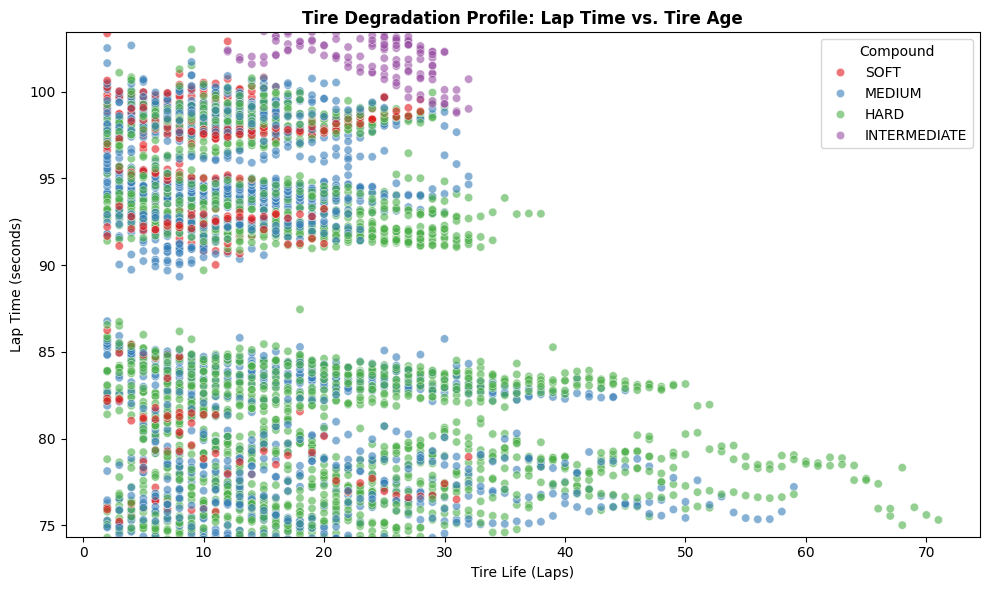

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("../reports/figures", exist_ok=True)

df = pd.read_csv("../data/processed/cleaned_laps.csv")
df_valid = df[df['IsAccurate'] == True].copy()

# Plot 3: Tire Degradation Profile
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_valid, 
    x='TyreLife', 
    y='LapTime_s', 
    hue='Compound', 
    alpha=0.6, 
    palette='Set1'
)
plt.title("Tire Degradation Profile: Lap Time vs. Tire Age", fontweight='bold')
plt.xlabel("Tire Life (Laps)")
plt.ylabel("Lap Time (seconds)")
plt.ylim(df_valid['LapTime_s'].quantile(0.01), df_valid['LapTime_s'].quantile(0.95))
plt.tight_layout()
plt.savefig("../reports/figures/tire_degradation_profile.png", dpi=300)
plt.show()

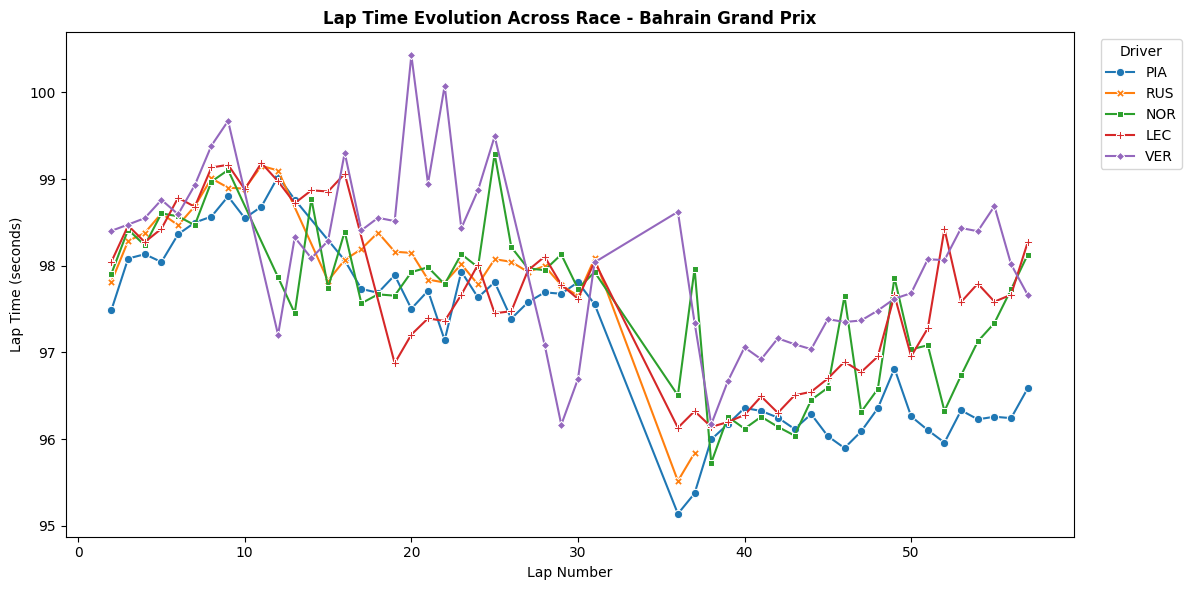

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("../reports/figures", exist_ok=True)

df = pd.read_csv("../data/processed/cleaned_laps.csv")
df_valid = df[df['IsAccurate'] == True].copy()

# Plot 2: Lap Evolution (Bahrain)
plt.figure(figsize=(12, 6))
df_bahrain = df_valid[(df_valid['Race'] == 'Bahrain') & (df_valid['LapTime_s'] < 115)]
top_drivers = ['VER', 'NOR', 'LEC', 'RUS', 'PIA']
df_bahrain_top = df_bahrain[df_bahrain['Driver'].isin(top_drivers)]

sns.lineplot(
    data=df_bahrain_top, 
    x='LapNumber', 
    y='LapTime_s', 
    hue='Driver', 
    style='Driver', 
    markers=True, 
    dashes=False
)
plt.title("Lap Time Evolution Across Race - Bahrain Grand Prix", fontweight='bold')
plt.xlabel("Lap Number")
plt.ylabel("Lap Time (seconds)")
plt.legend(title="Driver", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig("../reports/figures/lap_time_evolution.png", dpi=300)
plt.show()

C:\Users\Riya\AppData\Local\Temp\ipykernel_9112\3803678084.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_teams, x='Team', y='SpeedST', palette='plasma')


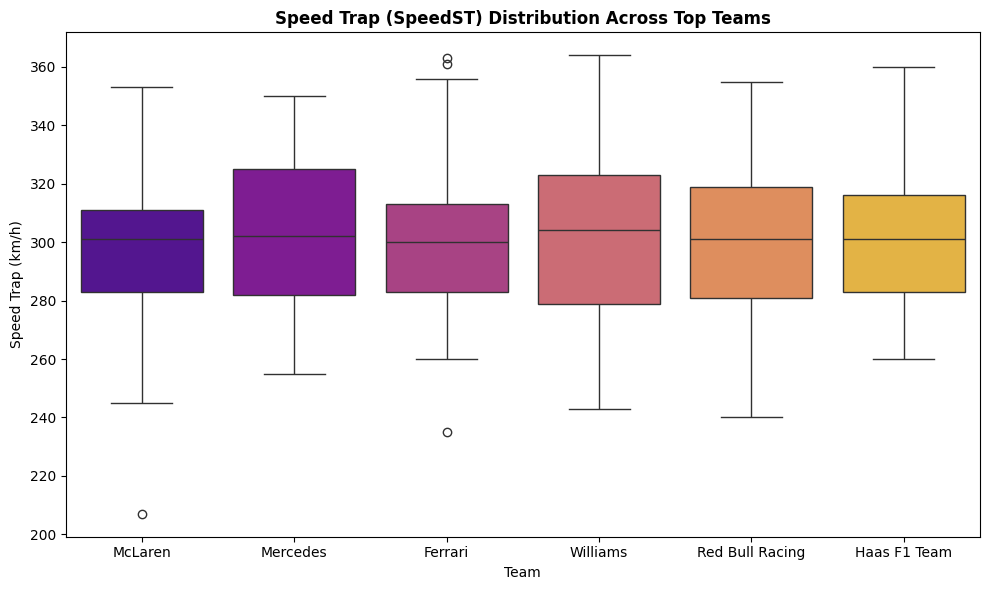

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Ensure output folder exists
os.makedirs("../reports/figures", exist_ok=True)

# Define the file path variable first
data_path = "../data/processed/cleaned_laps.csv"

# Load dataset using the defined path
df = pd.read_csv(data_path)
df_valid = df[df['IsAccurate'] == True].copy()

# Plot 1: Speed Trap Comparison
plt.figure(figsize=(10, 6))
top_teams = df_valid['Team'].value_counts().head(6).index
df_teams = df_valid[df_valid['Team'].isin(top_teams)]

sns.boxplot(data=df_teams, x='Team', y='SpeedST', palette='plasma')
plt.title("Speed Trap (SpeedST) Distribution Across Top Teams", fontweight='bold')
plt.xlabel("Team")
plt.ylabel("Speed Trap (km/h)")
plt.tight_layout()
plt.savefig("../reports/figures/top_speed_comparison.png", dpi=300)
plt.show()